In [ ]:
!pip install -q ucimlrepo imbalanced-learn shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = "/content/drive/MyDrive/shoppers_project"
os.makedirs(PROJECT_DIR, exist_ok=True)
print("Saving to:", PROJECT_DIR)

Mounted at /content/drive
Saving to: /content/drive/MyDrive/shoppers_project


In [ ]:
from ucimlrepo import fetch_ucirepo
ds = fetch_ucirepo(id=468)
df = pd.concat([ds.data.features, ds.data.targets], axis=1)

print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
df.info()
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nTarget distribution:\n", df["Revenue"].value_counts(normalize=True))
print("\nMonths present:", sorted(df["Month"].unique()))
print("\nVisitorType:\n", df["VisitorType"].value_counts())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [ ]:
n_before = len(df)
n_dupes = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {n_before} | duplicates removed: {n_dupes} | rows after: {len(df)}")

df["Revenue"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)

for c in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    df[c] = df[c].astype("category")

print("Rates in [0,1]:", df[["BounceRates", "ExitRates"]].apply(lambda s: s.between(0, 1).all()).all())
print("No negative durations:", (df.filter(like="Duration") >= 0).all().all())
print("No negative counts:", (df[["Administrative", "Informational", "ProductRelated"]] >= 0).all().all())
print("\nConversion rate after cleaning:", round(df["Revenue"].mean(), 4))

df.to_csv(f"{PROJECT_DIR}/shoppers_clean.csv", index=False)

Rows before: 12330 | duplicates removed: 125 | rows after: 12205
Rates in [0,1]: True
No negative durations: True
No negative counts: True

Conversion rate after cleaning: 0.1563


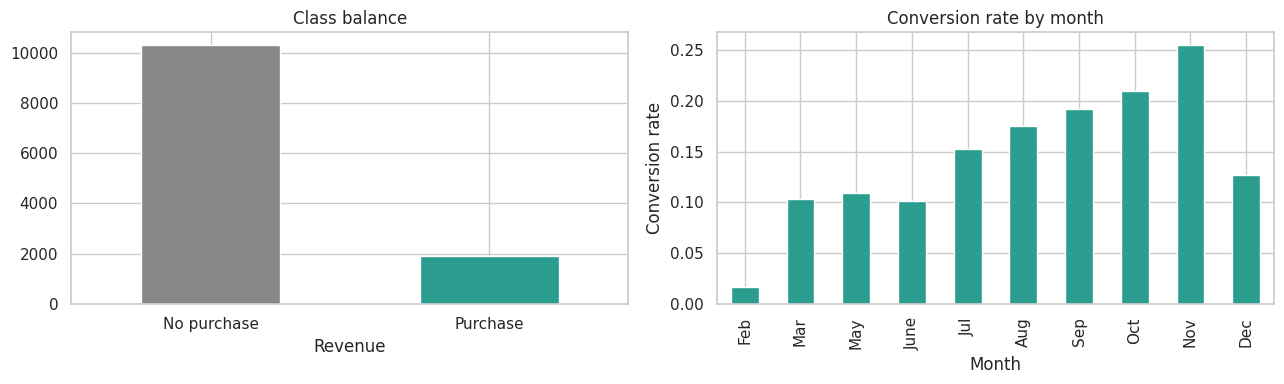

        mean  count
Month              
Feb    0.017    181
Mar    0.103   1860
May    0.110   3329
June   0.102    285
Jul    0.153    432
Aug    0.176    433
Sep    0.192    448
Oct    0.209    549
Nov    0.255   2982
Dec    0.127   1706


In [ ]:
# Month order (note: UCI spells June as "June", others abbreviated)
month_order = ["Jan","Feb","Mar","Apr","May","June","Jul","Aug","Sep","Oct","Nov","Dec"]
month_order = [m for m in month_order if m in df["Month"].unique()]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

df["Revenue"].value_counts().plot(kind="bar", ax=ax[0], color=["#888", "#2a9d8f"])
ax[0].set_xticklabels(["No purchase", "Purchase"], rotation=0)
ax[0].set_title("Class balance")

conv_month = df.groupby("Month")["Revenue"].agg(["mean", "count"]).reindex(month_order)
conv_month["mean"].plot(kind="bar", ax=ax[1], color="#2a9d8f")
ax[1].set_title("Conversion rate by month")
ax[1].set_ylabel("Conversion rate")
plt.tight_layout(); plt.show()

print(conv_month.round(3))

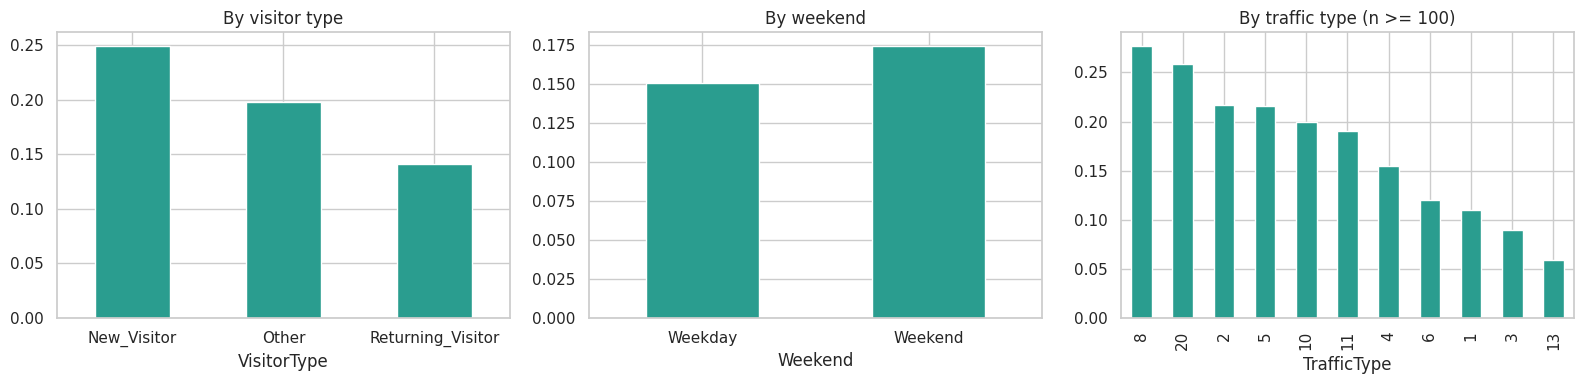

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

df.groupby("VisitorType")["Revenue"].mean().plot(kind="bar", ax=ax[0], color="#2a9d8f")
ax[0].set_title("By visitor type"); ax[0].tick_params(axis="x", rotation=0)

df.groupby("Weekend")["Revenue"].mean().plot(kind="bar", ax=ax[1], color="#2a9d8f")
ax[1].set_xticklabels(["Weekday", "Weekend"], rotation=0); ax[1].set_title("By weekend")

tt = df.groupby("TrafficType", observed=True)["Revenue"].agg(["mean", "count"])
tt = tt[tt["count"] >= 100].sort_values("mean", ascending=False)  # ignore tiny categories
tt["mean"].plot(kind="bar", ax=ax[2], color="#2a9d8f")
ax[2].set_title("By traffic type (n >= 100)")
plt.tight_layout(); plt.show()

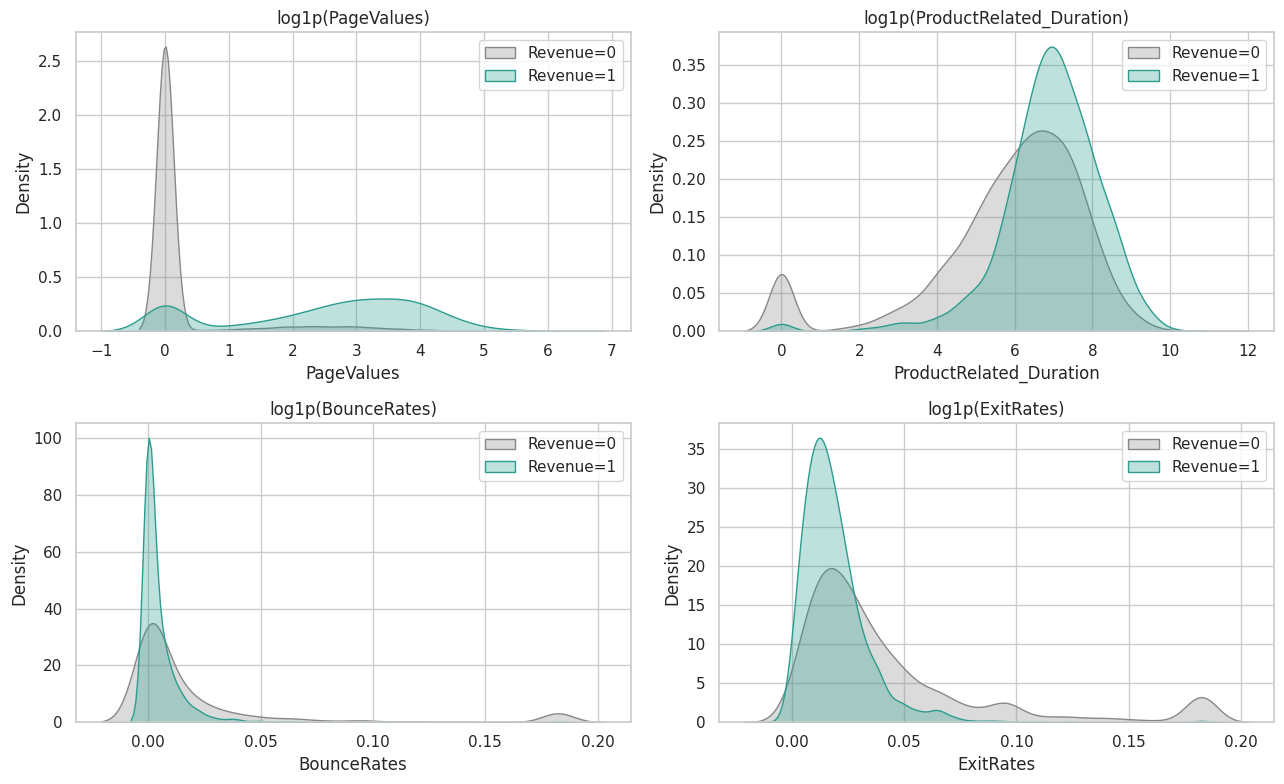

In [ ]:
feats = ["PageValues", "ProductRelated_Duration", "BounceRates", "ExitRates"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for a, f in zip(axes.ravel(), feats):
    for label, color in [(0, "#888"), (1, "#2a9d8f")]:
        sns.kdeplot(np.log1p(df.loc[df["Revenue"] == label, f]), ax=a,
                    label=f"Revenue={label}", color=color, fill=True, alpha=0.3)
    a.set_title(f"log1p({f})"); a.legend()
plt.tight_layout(); plt.show()

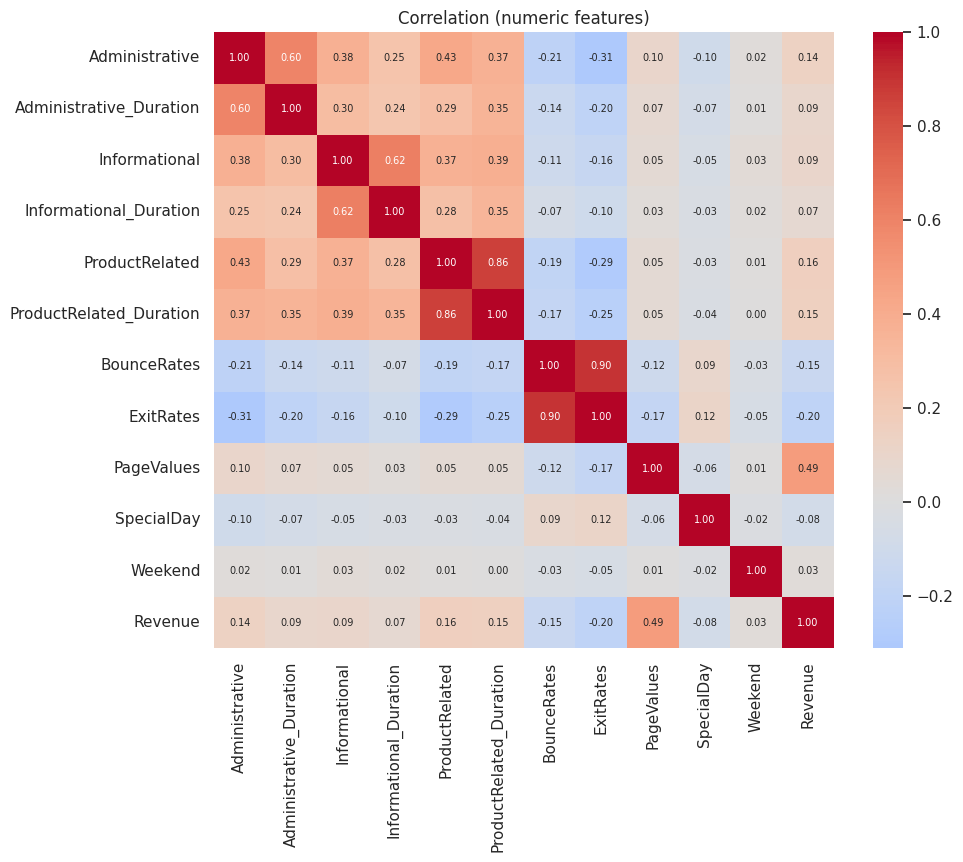

BounceRates vs ExitRates corr: 0.902

Share of sessions with PageValues == 0: 77.6%
Conversion when PageValues == 0: 3.9%
Conversion when PageValues  > 0: 56.3%


In [ ]:
num_cols = df.select_dtypes(include="number").columns
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation (numeric features)")
plt.show()

print("BounceRates vs ExitRates corr:", round(df["BounceRates"].corr(df["ExitRates"]), 3))

# Leakage preview
zero = df["PageValues"] == 0
print(f"\nShare of sessions with PageValues == 0: {zero.mean():.1%}")
print(f"Conversion when PageValues == 0: {df.loc[zero, 'Revenue'].mean():.1%}")
print(f"Conversion when PageValues  > 0: {df.loc[~zero, 'Revenue'].mean():.1%}")

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

X = df.drop(columns="Revenue")
y = df["Revenue"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(X_train.shape, X_test.shape)
print("Train positive rate:", round(y_train.mean(), 4), "| Test:", round(y_test.mean(), 4))

(9764, 17) (2441, 17)
Train positive rate: 0.1563 | Test: 0.1565


In [ ]:
skewed = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
          "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues"]
passthrough = ["SpecialDay", "Weekend"]
cats = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]

def make_preprocessor(drop=()):
    sk = [c for c in skewed if c not in drop]
    return ColumnTransformer([
        ("skewed", Pipeline([("log", FunctionTransformer(np.log1p)),
                             ("scale", StandardScaler())]), sk),
        ("pass", "passthrough", passthrough),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30), cats),
    ])

In [ ]:
# 1) Majority class: what "85% accuracy" really means
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Majority-class accuracy (train):", round(dummy.score(X_train, y_train), 4))

# 2) The one-line rule: PageValues > 0
rule = (X_train["PageValues"] > 0).astype(int)
print("\nRule 'PageValues > 0' on train:")
print("  precision:", round(precision_score(y_train, rule), 3))
print("  recall   :", round(recall_score(y_train, rule), 3))
print("  F1       :", round(f1_score(y_train, rule), 3))

Majority-class accuracy (train): 0.8437

Rule 'PageValues > 0' on train:
  precision: 0.561
  recall   : 0.805
  F1       : 0.661


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_lr(drop=()):
    pipe = Pipeline([
        ("prep", make_preprocessor(drop)),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)),
    ])
    r = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["average_precision", "roc_auc", "f1"])
    return {k: round(r[f"test_{k}"].mean(), 4) for k in ["average_precision", "roc_auc", "f1"]}

print("LR, all features        :", cv_lr())
print("LR, drop BounceRates    :", cv_lr(drop=("BounceRates",)))
print("LR, drop ExitRates      :", cv_lr(drop=("ExitRates",)))

LR, all features        : {'average_precision': np.float64(0.6636), 'roc_auc': np.float64(0.916), 'f1': np.float64(0.6463)}
LR, drop BounceRates    : {'average_precision': np.float64(0.6641), 'roc_auc': np.float64(0.9163), 'f1': np.float64(0.6473)}
LR, drop ExitRates      : {'average_precision': np.float64(0.6623), 'roc_auc': np.float64(0.9161), 'f1': np.float64(0.6504)}


In [ ]:
print("Shapes:", X_train.shape, X_test.shape)
print("Pos rate train/test:", round(y_train.mean(), 4), round(y_test.mean(), 4))
print("Majority acc (train):", round(dummy.score(X_train, y_train), 4))
print("Rule PageValues>0 -> P/R/F1:",
      round(precision_score(y_train, rule), 3),
      round(recall_score(y_train, rule), 3),
      round(f1_score(y_train, rule), 3))
print("LR all      :", cv_lr())
print("LR -Bounce  :", cv_lr(drop=("BounceRates",)))
print("LR -Exit    :", cv_lr(drop=("ExitRates",)))
print(df.groupby("VisitorType")["Revenue"].agg(["mean", "count"]).round(3))

Shapes: (9764, 17) (2441, 17)
Pos rate train/test: 0.1563 0.1565
Majority acc (train): 0.8437
Rule PageValues>0 -> P/R/F1: 0.561 0.805 0.661
LR all      : {'average_precision': np.float64(0.6636), 'roc_auc': np.float64(0.916), 'f1': np.float64(0.6463)}
LR -Bounce  : {'average_precision': np.float64(0.6641), 'roc_auc': np.float64(0.9163), 'f1': np.float64(0.6473)}
LR -Exit    : {'average_precision': np.float64(0.6623), 'roc_auc': np.float64(0.9161), 'f1': np.float64(0.6504)}
                    mean  count
VisitorType                    
New_Visitor        0.249   1693
Other              0.198     81
Returning_Visitor  0.141  10431


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "LR": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
    "RF": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                 min_samples_leaf=3, n_jobs=-1, random_state=SEED),
    "XGB": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                         scale_pos_weight=pos_weight, eval_metric="aucpr",
                         n_jobs=-1, random_state=SEED),
}

results = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    r = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["average_precision", "roc_auc", "f1"])
    results[name] = {k: round(r[f"test_{k}"].mean(), 4) for k in ["average_precision", "roc_auc", "f1"]}
    results[name]["PR_std"] = round(r["test_average_precision"].std(), 4)
    print(name, results[name])

LR {'average_precision': np.float64(0.6636), 'roc_auc': np.float64(0.916), 'f1': np.float64(0.6463), 'PR_std': np.float64(0.0226)}
RF {'average_precision': np.float64(0.7371), 'roc_auc': np.float64(0.9284), 'f1': np.float64(0.6862), 'PR_std': np.float64(0.0214)}
XGB {'average_precision': np.float64(0.7448), 'roc_auc': np.float64(0.9286), 'f1': np.float64(0.6559), 'PR_std': np.float64(0.0261)}


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "LR": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
    "RF": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                 min_samples_leaf=3, n_jobs=-1, random_state=SEED),
    "XGB": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                         scale_pos_weight=pos_weight, eval_metric="aucpr",
                         n_jobs=-1, random_state=SEED),
}

results = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    r = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["average_precision", "roc_auc", "f1"])
    results[name] = {k: round(r[f"test_{k}"].mean(), 4) for k in ["average_precision", "roc_auc", "f1"]}
    results[name]["PR_std"] = round(r["test_average_precision"].std(), 4)
    print(name, results[name])

LR {'average_precision': np.float64(0.6636), 'roc_auc': np.float64(0.916), 'f1': np.float64(0.6463), 'PR_std': np.float64(0.0226)}
RF {'average_precision': np.float64(0.7371), 'roc_auc': np.float64(0.9284), 'f1': np.float64(0.6862), 'PR_std': np.float64(0.0214)}
XGB {'average_precision': np.float64(0.7448), 'roc_auc': np.float64(0.9286), 'f1': np.float64(0.6559), 'PR_std': np.float64(0.0261)}


In [ ]:
for name, clf in models.items():
    pipe = Pipeline([("prep", make_preprocessor(drop=("PageValues",))), ("clf", clf)])
    r = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["average_precision", "roc_auc", "f1"])
    print(name, "(no PageValues)",
          {k: round(r[f"test_{k}"].mean(), 4) for k in ["average_precision", "roc_auc", "f1"]})

LR (no PageValues) {'average_precision': np.float64(0.3301), 'roc_auc': np.float64(0.7484), 'f1': np.float64(0.3913)}
RF (no PageValues) {'average_precision': np.float64(0.3842), 'roc_auc': np.float64(0.7779), 'f1': np.float64(0.3785)}
XGB (no PageValues) {'average_precision': np.float64(0.3717), 'roc_auc': np.float64(0.7731), 'f1': np.float64(0.4175)}


In [ ]:
from sklearn.model_selection import cross_val_score
for name, clf in models.items():
    pipe = Pipeline([("prep", make_preprocessor(drop=("PageValues",))), ("clf", clf)])
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    print(name, np.round(s, 3), "std:", round(s.std(), 3))

LR [0.336 0.285 0.386 0.313 0.33 ] std: 0.033
RF [0.369 0.339 0.402 0.418 0.393] std: 0.028
XGB [0.357 0.354 0.39  0.389 0.369] std: 0.015


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "LR": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
    "RF": RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                 min_samples_leaf=3, n_jobs=-1, random_state=SEED),
    "XGB": XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4,
                         scale_pos_weight=pos_weight, eval_metric="aucpr",
                         n_jobs=-1, random_state=SEED),
}

import time
for name, clf in models.items():
    t = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    print(name, "(with PageValues) per fold:", np.round(s, 3),
          "mean:", round(s.mean(), 4), f"| {time.time()-t:.0f}s")

LR (with PageValues) per fold: [0.651 0.625 0.675 0.683 0.683] mean: 0.6636 | 4s
RF (with PageValues) per fold: [0.713 0.719 0.745 0.761 0.731] mean: 0.7338 | 31s
XGB (with PageValues) per fold: [0.712 0.741 0.753 0.792 0.746] mean: 0.7485 | 2s


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
import time

xgb_space = {
    "clf__n_estimators": randint(150, 500),
    "clf__learning_rate": uniform(0.01, 0.1),
    "clf__max_depth": randint(2, 6),
    "clf__min_child_weight": randint(1, 10),
    "clf__subsample": uniform(0.6, 0.4),
    "clf__colsample_bytree": uniform(0.5, 0.5),
}

tuned = {}
for label, drop in [("with PageValues", ()), ("no PageValues", ("PageValues",))]:
    t = time.time()
    pipe = Pipeline([("prep", make_preprocessor(drop)),
                     ("clf", XGBClassifier(scale_pos_weight=pos_weight, eval_metric="aucpr",
                                           n_jobs=-1, random_state=SEED))])
    s = RandomizedSearchCV(pipe, xgb_space, n_iter=25, cv=cv,
                           scoring="average_precision", random_state=SEED, n_jobs=1)
    s.fit(X_train, y_train)
    tuned[label] = s
    print(f"XGB {label}: best CV PR-AUC = {s.best_score_:.4f} | {time.time()-t:.0f}s")
    print("   params:", {k.replace('clf__', ''): (round(v, 3) if isinstance(v, float) else v)
                         for k, v in s.best_params_.items()})

XGB with PageValues: best CV PR-AUC = 0.7522 | 105s
   params: {'colsample_bytree': np.float64(0.886), 'learning_rate': np.float64(0.03), 'max_depth': 5, 'min_child_weight': 3, 'n_estimators': 230, 'subsample': np.float64(0.885)}
XGB no PageValues: best CV PR-AUC = 0.3816 | 95s
   params: {'colsample_bytree': np.float64(0.953), 'learning_rate': np.float64(0.037), 'max_depth': 4, 'min_child_weight': 9, 'n_estimators': 265, 'subsample': np.float64(0.741)}


In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score

best = {k: v.best_estimator_ for k, v in tuned.items()}

oof = {}
for label, est in best.items():
    oof[label] = cross_val_predict(est, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    print(label, "| OOF PR-AUC:", round(average_precision_score(y_train, oof[label]), 4))

with PageValues | OOF PR-AUC: 0.7499
no PageValues | OOF PR-AUC: 0.3751


In [ ]:
# ASSUMPTION (not measured): a missed buyer (FN) costs R times a wasted intervention (FP).
ratios = [3, 5, 10]
thresholds = np.linspace(0.02, 0.98, 97)

def cost_curve(y_true, p, R):
    y_true = np.asarray(y_true)
    out = []
    for t in thresholds:
        pred = p >= t
        fp = ((pred == 1) & (y_true == 0)).sum()
        fn = ((pred == 0) & (y_true == 1)).sum()
        out.append(fp * 1 + fn * R)
    return np.array(out)

rows = []
for label, p in oof.items():
    for R in ratios:
        c = cost_curve(y_train, p, R)
        t_best = thresholds[c.argmin()]
        pred = p >= t_best
        rows.append({"model": label, "R (FN:FP)": R, "best_thr": round(t_best, 2),
                     "precision": round(precision_score(y_train, pred), 3),
                     "recall": round(recall_score(y_train, pred), 3),
                     "flagged_%": round(pred.mean() * 100, 1),
                     "cost_vs_flag_none_%": round(100 * c.min() / ((y_train == 1).sum() * R), 1)})
print(pd.DataFrame(rows).to_string(index=False))

          model  R (FN:FP)  best_thr  precision  recall  flagged_%  cost_vs_flag_none_%
with PageValues          3      0.54      0.575   0.808       22.0                 39.1
with PageValues          5      0.51      0.558   0.821       23.0                 30.9
with PageValues         10      0.25      0.395   0.936       37.1                 20.8
  no PageValues          3      0.58      0.341   0.605       27.7                 78.4
  no PageValues          5      0.52      0.308   0.691       35.0                 61.9
  no PageValues         10      0.33      0.245   0.900       57.5                 37.8


In [ ]:
from sklearn.metrics import roc_auc_score

rows_df = pd.DataFrame(rows)
test_p = {label: est.predict_proba(X_test)[:, 1] for label, est in best.items()}
rng = np.random.default_rng(SEED)

def boot_ci(y, p, n=1000):
    y = np.asarray(y); s = []
    for _ in range(n):
        b = rng.choice(len(y), len(y), replace=True)
        s.append(average_precision_score(y[b], p[b]))
    return np.percentile(s, [2.5, 97.5]).round(3)

print("Test positive rate:", round(y_test.mean(), 4))
for label, p in test_p.items():
    print(f"{label}: PR-AUC {average_precision_score(y_test, p):.4f} "
          f"(95% CI {boot_ci(y_test, p)}) | ROC-AUC {roc_auc_score(y_test, p):.4f}")

# Fixed thresholds from OOF, applied once to test
n_pos, n_neg = int(y_test.sum()), int((y_test == 0).sum())
out = []
for _, r in rows_df.iterrows():
    p = test_p[r["model"]]; pred = p >= r["best_thr"]
    fp = int(((pred == 1) & (y_test == 0)).sum()); fn = int(((pred == 0) & (y_test == 1)).sum())
    R = r["R (FN:FP)"]; cost = fp + R * fn
    out.append({"model": r["model"], "R": R, "thr": r["best_thr"],
                "precision": round(precision_score(y_test, pred), 3),
                "recall": round(recall_score(y_test, pred), 3),
                "flagged_%": round(pred.mean() * 100, 1),
                "cost/do-nothing_%": round(100 * cost / (R * n_pos), 1),
                "cost/flag-all_%": round(100 * cost / n_neg, 1)})
print(pd.DataFrame(out).to_string(index=False))

# One-line rule on test, for reference
rule_t = (X_test["PageValues"] > 0).astype(int)
print("\nRule PageValues>0 on test: P/R/F1 =",
      round(precision_score(y_test, rule_t), 3), round(recall_score(y_test, rule_t), 3),
      round(f1_score(y_test, rule_t), 3))

Test positive rate: 0.1565
with PageValues: PR-AUC 0.7577 (95% CI [0.715 0.8  ]) | ROC-AUC 0.9378
no PageValues: PR-AUC 0.3762 (95% CI [0.331 0.426]) | ROC-AUC 0.7949
          model  R  thr  precision  recall  flagged_%  cost/do-nothing_%  cost/flag-all_%
with PageValues  3 0.54      0.567   0.819       22.6               38.9             21.7
with PageValues  5 0.51      0.562   0.843       23.5               28.8             26.8
with PageValues 10 0.25      0.389   0.950       38.2               19.9             36.9
  no PageValues  3 0.58      0.348   0.631       28.4               76.4             42.5
  no PageValues  5 0.52      0.311   0.728       36.7               59.5             55.2
  no PageValues 10 0.33      0.247   0.932       59.0               35.2             65.3

Rule PageValues>0 on test: P/R/F1 = 0.571 0.812 0.67


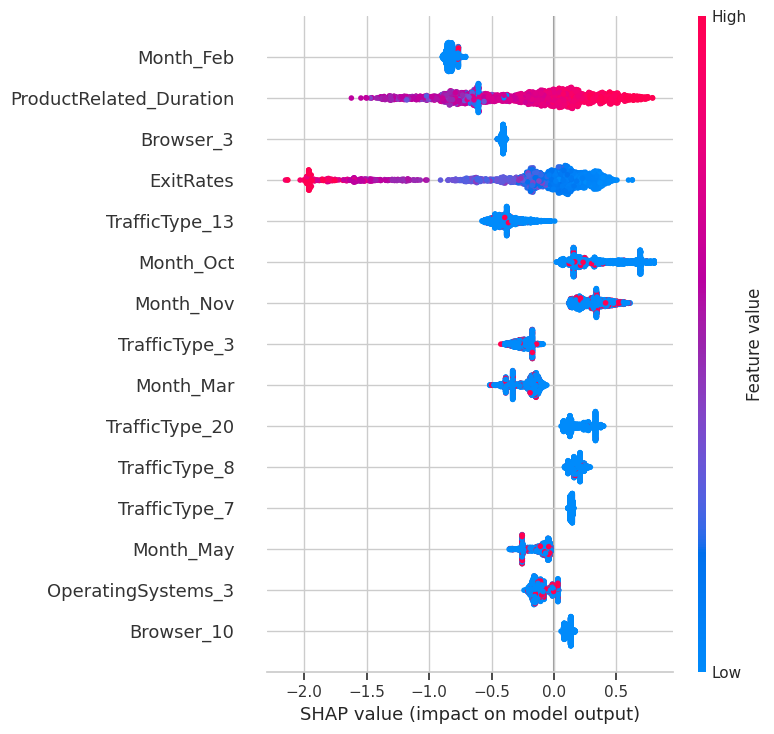

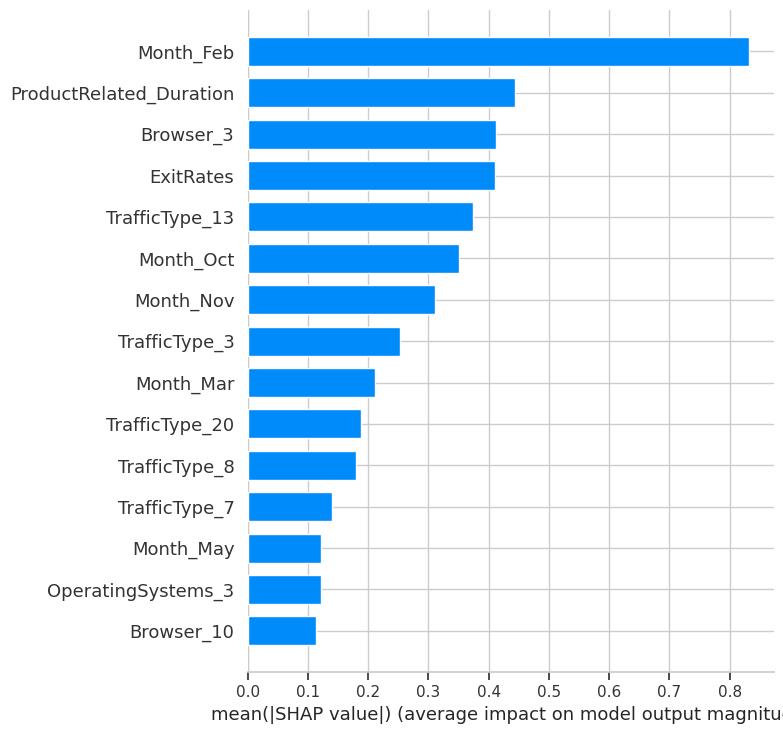

In [ ]:
import shap
from scipy.sparse import issparse

est = best["no PageValues"]
prep, clf = est.named_steps["prep"], est.named_steps["clf"]

Xt = prep.transform(X_test)
Xt = Xt.toarray() if issparse(Xt) else np.asarray(Xt)

# Build names manually, in the ColumnTransformer's order: skewed -> pass -> cat
skewed_used = [c for c in skewed if c != "PageValues"]
ohe = prep.named_transformers_["cat"]
cat_names = list(ohe.get_feature_names_out(cats))
names = skewed_used + passthrough + cat_names

assert Xt.shape[1] == len(names), (Xt.shape[1], len(names))
Xt_df = pd.DataFrame(Xt, columns=names)

explainer = shap.TreeExplainer(clf)
sv = explainer.shap_values(Xt_df)

shap.summary_plot(sv, Xt_df, max_display=15)
shap.summary_plot(sv, Xt_df, plot_type="bar", max_display=15)

In [ ]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(est, X_test, y_test, scoring="average_precision",
                            n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"feature": X_test.columns, "mean": pi.importances_mean,
                    "std": pi.importances_std}).sort_values("mean", ascending=False)
print(imp.round(4).to_string(index=False))

                feature    mean    std
ProductRelated_Duration  0.0794 0.0159
              ExitRates  0.0738 0.0201
                  Month  0.0588 0.0132
         ProductRelated  0.0184 0.0023
            VisitorType  0.0151 0.0007
            BounceRates  0.0100 0.0059
Administrative_Duration  0.0093 0.0030
            TrafficType  0.0082 0.0091
       OperatingSystems  0.0080 0.0023
         Administrative  0.0048 0.0020
                 Region  0.0022 0.0008
             SpecialDay  0.0016 0.0043
                Weekend  0.0015 0.0012
             PageValues  0.0000 0.0000
                Browser -0.0005 0.0013
          Informational -0.0010 0.0012
 Informational_Duration -0.0016 0.0017


In [ ]:
from sklearn.base import clone

cats_nm = [c for c in cats if c != "Month"]
prep_nm = ColumnTransformer([
    ("skewed", Pipeline([("log", FunctionTransformer(np.log1p)),
                         ("scale", StandardScaler())]),
     [c for c in skewed if c != "PageValues"]),
    ("pass", "passthrough", passthrough),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30), cats_nm),
])
clf_nm = clone(best["no PageValues"].named_steps["clf"])
pipe_nm = Pipeline([("prep", prep_nm), ("clf", clf_nm)])

s_nm = cross_val_score(pipe_nm, X_train, y_train, cv=cv, scoring="average_precision")
s_base = cross_val_score(clone(best["no PageValues"]), X_train, y_train, cv=cv, scoring="average_precision")
print("With Month   :", np.round(s_base, 3), "mean", round(s_base.mean(), 4))
print("Without Month:", np.round(s_nm, 3), "mean", round(s_nm.mean(), 4))

With Month   : [0.382 0.344 0.404 0.401 0.377] mean 0.3816
Without Month: [0.349 0.312 0.39  0.329 0.325] mean 0.3412


In [ ]:
def binned_view(col, q=8):
    j = names.index(col)
    d = pd.DataFrame({"raw": X_test[col].values, "shap": sv[:, j], "y": y_test.values})
    d["bin"] = pd.qcut(d["raw"], q=q, duplicates="drop")
    print(f"\n{col}")
    print(d.groupby("bin", observed=True)
            .agg(n=("y", "size"), conv=("y", "mean"), mean_shap=("shap", "mean"))
            .round(3).to_string())

binned_view("ProductRelated_Duration")
binned_view("ExitRates")

# Which months does the model lean on?
rows = []
for n in [c for c in names if c.startswith("Month_")]:
    j = names.index(n)
    on = Xt_df[n].values == 1
    rows.append({"month": n.replace("Month_", ""), "n_test": int(on.sum()),
                 "conv": round(float(y_test.values[on].mean()), 3) if on.sum() else None,
                 "mean_shap": round(float(sv[on, j].mean()), 3) if on.sum() else None})
print("\n", pd.DataFrame(rows).to_string(index=False))


ProductRelated_Duration
                         n   conv  mean_shap
bin                                         
(-0.001, 63.0]         307  0.042     -0.743
(63.0, 192.75]         305  0.052     -0.963
(192.75, 360.75]       304  0.105     -0.591
(360.75, 586.333]      305  0.167     -0.325
(586.333, 908.013]     305  0.203     -0.052
(908.013, 1449.0]      305  0.207      0.093
(1449.0, 2524.719]     305  0.207      0.229
(2524.719, 27009.859]  305  0.269      0.489

ExitRates
                    n   conv  mean_shap
bin                                    
(-0.001, 0.0087]  310  0.287      0.253
(0.0087, 0.0135]  301  0.249      0.282
(0.0135, 0.0194]  305  0.233      0.127
(0.0194, 0.0254]  305  0.154      0.063
(0.0254, 0.0333]  325  0.157     -0.076
(0.0333, 0.0475]  285  0.109     -0.287
(0.0475, 0.08]    305  0.046     -0.413
(0.08, 0.2]       305  0.013     -1.732

 month  n_test  conv  mean_shap
  Aug      73 0.192      0.013
  Dec     343 0.108     -0.096
  Feb      37 0.000

In [ ]:
# 1) SHAP grouped by original column
imp_feat = pd.Series(np.abs(sv).mean(axis=0), index=names).sort_values(ascending=False)
def group_of(n):
    for c in cats:
        if n.startswith(c + "_"):
            return c
    return n
print("SHAP by original column:\n",
      imp_feat.groupby(group_of).sum().sort_values(ascending=False).round(4).head(8).to_string())

# 2) Single-feature rankings on TRAIN (nothing fitted, test untouched)
print("\nSingle-feature PR-AUC on train (base rate", round(y_train.mean(), 3), ")")
for col, sign in [("ExitRates", -1), ("ProductRelated_Duration", 1), ("ProductRelated", 1)]:
    print(f"  {col}: {average_precision_score(y_train, sign * X_train[col]):.3f}")

# 3) Extreme bins
hi = X_test["ExitRates"] > 0.08
print("\nExitRates > 0.08: n =", int(hi.sum()), "| buyers =", int(y_test[hi].sum()))
print(X_test.loc[hi, ["ProductRelated", "ProductRelated_Duration", "BounceRates"]]
      .describe().loc[["min", "50%", "max"]].round(3))
print("\nDuration > 2524.7s: n =", int((X_test["ProductRelated_Duration"] > 2524.7).sum()),
      "| sessions over 3h:", int((X_test["ProductRelated_Duration"] > 10800).sum()),
      "| max hours:", round(X_test["ProductRelated_Duration"].max() / 3600, 1))

# 4) Decile lift, primary model, test set
p = test_p["no PageValues"]
d = pd.DataFrame({"p": p, "y": y_test.values})
d["decile"] = pd.qcut(d["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = d.groupby("decile", observed=True).agg(n=("y", "size"), buyers=("y", "sum"), conv=("y", "mean"))
lift["lift"] = lift["conv"] / y_test.mean()
lift["cum_recall"] = lift["buyers"].cumsum() / lift["buyers"].sum()
print("\n", lift.round(3).to_string())

SHAP by original column:
 Month                      2.1700
TrafficType                1.4863
Browser                    0.8968
ProductRelated_Duration    0.4441
ExitRates                  0.4102
Region                     0.2266
OperatingSystems           0.1977
BounceRates                0.1107

Single-feature PR-AUC on train (base rate 0.156 )
  ExitRates: 0.259
  ProductRelated_Duration: 0.244
  ProductRelated: 0.238

ExitRates > 0.08: n = 305 | buyers = 4
     ProductRelated  ProductRelated_Duration  BounceRates
min             0.0                     0.00          0.0
50%             3.0                    20.20          0.1
max            73.0                  4175.75          0.2

Duration > 2524.7s: n = 306 | sessions over 3h: 16 | max hours: 7.5

           n  buyers   conv   lift  cum_recall
decile                                       
1       245     109  0.445  2.843       0.285
2       244      76  0.311  1.990       0.484
3       244      62  0.254  1.624       0.647
4 

In [ ]:
# 1) Correct grouped SHAP: sum signed SHAP within each original column, per session, then take |mean|
sv_df = pd.DataFrame(sv, columns=names)
groups = {}
for n in names:
    groups.setdefault(group_of(n), []).append(n)
grp = pd.DataFrame({g: sv_df[cols].sum(axis=1) for g, cols in groups.items()})
print("Corrected grouped SHAP (mean |sum| per session):")
print(grp.abs().mean().sort_values(ascending=False).round(3).head(10).to_string())

# 2) CV check: drop the four technical ID columns (train only)
id_cols = ["Browser", "OperatingSystems", "Region", "TrafficType"]
cats_core = [c for c in cats if c not in id_cols]
prep_core = ColumnTransformer([
    ("skewed", Pipeline([("log", FunctionTransformer(np.log1p)),
                         ("scale", StandardScaler())]),
     [c for c in skewed if c != "PageValues"]),
    ("pass", "passthrough", passthrough),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30), cats_core),
])
pipe_core = Pipeline([("prep", prep_core),
                      ("clf", clone(best["no PageValues"].named_steps["clf"]))])
s_core = cross_val_score(pipe_core, X_train, y_train, cv=cv, scoring="average_precision")
print("\nAll features  :", np.round(s_base, 3), "mean", round(s_base.mean(), 4))
print("No ID columns :", np.round(s_core, 3), "mean", round(s_core.mean(), 4))

# 3) ExitRates-only decile recall on test, for a like-for-like comparison with the model
d2 = pd.DataFrame({"s": -X_test["ExitRates"].values, "y": y_test.values})
d2["decile"] = pd.qcut(d2["s"].rank(method="first", ascending=False), 10, labels=range(1, 11))
l2 = d2.groupby("decile", observed=True).agg(buyers=("y", "sum"))
l2["cum_recall"] = l2["buyers"].cumsum() / l2["buyers"].sum()
print("\nExitRates-only:\n", l2.round(3).to_string())

Corrected grouped SHAP (mean |sum| per session):
ProductRelated_Duration    0.444
Month                      0.428
ExitRates                  0.410
Browser                    0.207
TrafficType                0.160
BounceRates                0.111
Administrative             0.109
OperatingSystems           0.108
ProductRelated             0.089
SpecialDay                 0.071

All features  : [0.382 0.344 0.404 0.401 0.377] mean 0.3816
No ID columns : [0.366 0.336 0.391 0.403 0.376] mean 0.3743

ExitRates-only:
         buyers  cum_recall
decile                    
1           71       0.186
2           65       0.356
3           59       0.510
4           48       0.636
5           39       0.738
6           41       0.846
7           32       0.929
8           17       0.974
9            8       0.995
10           2       1.000


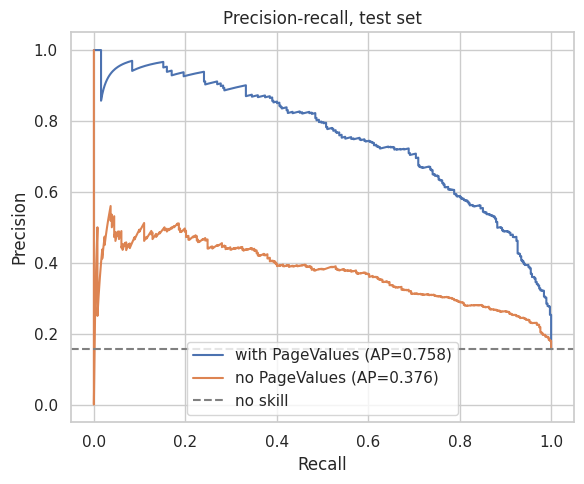

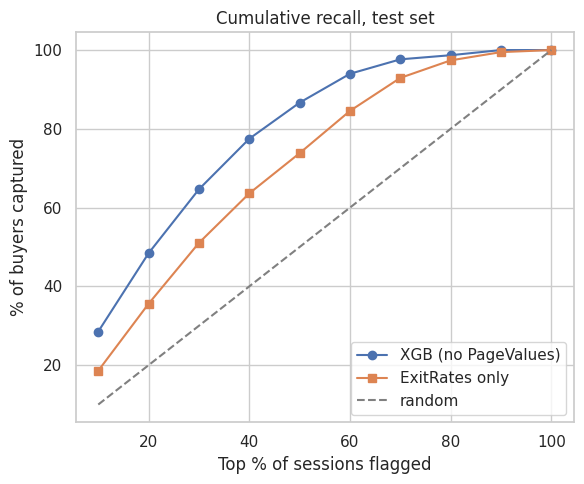

In [ ]:
import joblib
joblib.dump(best["no PageValues"], f"{PROJECT_DIR}/xgb_no_pagevalues.joblib")
joblib.dump(best["with PageValues"], f"{PROJECT_DIR}/xgb_with_pagevalues.joblib")

fig_dir = f"{PROJECT_DIR}/figures"; os.makedirs(fig_dir, exist_ok=True)

# PR curves on test
plt.figure(figsize=(6, 5))
for label, p in test_p.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    plt.plot(rc, pr, label=f"{label} (AP={average_precision_score(y_test, p):.3f})")
plt.axhline(y_test.mean(), ls="--", c="gray", label="no skill")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend()
plt.title("Precision-recall, test set"); plt.tight_layout()
plt.savefig(f"{fig_dir}/pr_curves.png", dpi=200); plt.show()

# Cumulative recall: model vs ExitRates-only vs random
x = np.arange(1, 11) * 10
plt.figure(figsize=(6, 5))
plt.plot(x, lift["cum_recall"].values * 100, marker="o", label="XGB (no PageValues)")
plt.plot(x, l2["cum_recall"].values * 100, marker="s", label="ExitRates only")
plt.plot(x, x, ls="--", c="gray", label="random")
plt.xlabel("Top % of sessions flagged"); plt.ylabel("% of buyers captured")
plt.legend(); plt.title("Cumulative recall, test set"); plt.tight_layout()
plt.savefig(f"{fig_dir}/cum_recall.png", dpi=200); plt.show()

# SHAP summary figures (sv, Xt_df from Cell 20)
shap.summary_plot(sv, Xt_df, max_display=15, show=False)
plt.tight_layout(); plt.savefig(f"{fig_dir}/shap_beeswarm.png", dpi=200); plt.close()

In [ ]:
!pip freeze | grep -iE "^(pandas|numpy|scipy|scikit-learn|xgboost|shap|matplotlib|seaborn|joblib)=="

joblib==1.6.0
matplotlib==3.10.0
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
scipy==1.16.3
seaborn==0.13.2
shap==0.54.1
xgboost==3.4.1
